### Package versions

Run the cell below to record the exact package versions used to generate the results in this notebook.


In [1]:
# --- Environment / package versions (added for reproducibility) ---
import sys
try:
    from importlib.metadata import version, PackageNotFoundError
except ImportError:  # Python < 3.8
    from importlib_metadata import version, PackageNotFoundError
print("Python:", sys.version.split()[0])
for _pkg in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "seaborn", "gseapy", "pyliftover", "openpyxl", "requests", "pyBigWig", "pyreadr", "adjustText", "pypdf"]:
    try:
        print(f"{_pkg}: {version(_pkg)}")
    except PackageNotFoundError:
        pass


Python: 3.14.4
numpy: 2.4.4
pandas: 3.0.2
scipy: 1.17.1
statsmodels: 0.14.6
matplotlib: 3.10.9
seaborn: 0.13.2
gseapy: 1.3.0
pyliftover: 0.4.1
openpyxl: 3.1.5
requests: 2.34.2
pyBigWig: 0.3.25
pyreadr: 0.5.6
adjustText: 1.3.0
pypdf: 6.14.2


# SLC38A4-KO RNA-seq: dedifferentiation and disease-signature concordance (Fig. 4)

Single analysis notebook for the *dedifferentiation* panels of the SLC38A4-knockout Huh7.5 RNA-seq
experiment — the HNF4A adult-to-foetal isoform switch, the proliferation-arrest gene signature, and
concordance of the knockout transcriptome with the SAH liver disease signature.

**Outputs**
- **Fig 4B** — HNF4A foetal (P2) isoform fraction from RNA-seq promoter coverage (+ supplementary
  P1/P2-separate panel).
- **Fig S10D** — CCK-8 proliferation curve, individual wells + mean ± SEM, with per-timepoint
  WT-vs-KO significance (Welch's t-test on log2-transformed values relative to baseline; n=7-8
  wells/group/timepoint). *(Note: this panel moved out of the main Fig. 4 body to Supplementary Fig.
  S10D in the current manuscript -- the section header and savefig filename below already reflect
  this; this overview note previously called it "Fig 4D", which was stale.)*
- **Fig 4D** — cell-cycle/checkpoint gene signature (proliferation drivers vs checkpoint-activation genes
  vs CDK inhibitors/senescence markers) from the KO RNA-seq. *(Was labelled "Fig 4E" in an earlier
  draft of this overview note; the letter shifted when CCK-8 moved out to Fig S10D above.)*
- **Fig 4E** — pre-ranked GSEA: does the SLC38A4-KO transcriptome recapitulate the SAH liver signature?
  (classic running-enrichment plot + compact NES-bar alternative). *(Was labelled "Fig 4F" previously,
  for the same reason.)*

Clone order: **KO 1 = C12, KO 2 = P1.7** throughout.

**Inputs**: `Fig4B_HNF4A_isoform_usage_data.csv`; `Fig_S10D_CCK8_proliferation_data.csv` (well-level CCK-8 data,
feeds Fig S10D above) and `Fig3C_limma_KO_vs_WT_combined_mincount10.csv`; and the pre-computed GSEA CSVs
`Fig4E_GSEA_stats.csv`, `Fig4E_GSEA_running.csv`, `Fig4E_SAH_signature_genes.csv` (feed Fig 4E above --
see the GSEA section for how to regenerate these from the raw DE tables).


In [2]:
import os
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D

AXTITLE = 11
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.linewidth': 1.0,
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.major.width': 1.0, 'ytick.major.width': 1.0,
    'xtick.major.size': 4, 'ytick.major.size': 4,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.unicode_minus': False,
})
COLORS = {'WT': '#AAAAAA', 'KO1': '#D73027', 'KO2': '#FC8D59', 'KO 1': '#D73027', 'KO 2': '#FC8D59'}
ORDER  = ['WT', 'KO1', 'KO2']
XLAB   = {'WT': 'WT', 'KO1': 'KO 1', 'KO2': 'KO 2'}

def sem(x): return x.std(ddof=1) / np.sqrt(len(x))
def fmt_p(p): return f'p = {p:.1e}' if p < 1e-4 else f'p = {p:.4f}'

def sig_bar(ax, x1, x2, y, p, h, fs=7):
    """Horizontal significance bracket from x1 to x2 at height y, p-value above."""
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=0.9, color='black', clip_on=False)
    ax.text((x1 + x2) / 2, y + h, fmt_p(p), ha='center', va='bottom', fontsize=fs)


# Supplementary · Identity / dedifferentiation markers (RT-qPCR)

Progenitor (**EPCAM**) and mesenchymal (**VIM**) markers, and the adult (**HNF4α-P1**) vs foetal
(**HNF4α-P2**) *HNF4A* isoforms, in WT vs KO 1 vs KO 2. Expression normalised to WT (= 1); n = 6 per group.
Clone order **KO 1 = C12, KO 2 = P1.7**.

**Statistics:** unpaired Welch's t-test on log₂-transformed relative expression (WT vs each KO clone);
exact p-values shown. Input: `Fig_S10A_identity_markers_qPCR_data.csv`.

In [3]:
qpcr = pd.read_csv('Fig_S10A_identity_markers_qPCR_data.csv')
GENES  = ['EPCAM', 'VIM', 'HNF4a-P1', 'HNF4a-P2']
LABELS = ['EPCAM', 'VIM', 'HNF4α-P1', 'HNF4α-P2']
GROUP_ORDER = ['WT', 'KO 1', 'KO 2']
def sem(x): return x.std(ddof=1) / np.sqrt(len(x))
def fmt_p(p): return f'p = {p:.1e}' if p < 1e-4 else f'p = {p:.4f}'
def sig_bar(ax, x1, x2, y, p, h, fs=7):
    """Horizontal significance bracket from x1 to x2 at height y, p-value above."""
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=0.9, color='black', clip_on=False)
    ax.text((x1 + x2) / 2, y + h, fmt_p(p), ha='center', va='bottom', fontsize=fs)

# stats table (Welch's t-test on log2, WT vs each KO)
rows = []
for g in GENES:
    wt = qpcr[(qpcr.gene == g) & (qpcr.group == 'WT')]['rel_expression'].values
    for ko in ['KO 1', 'KO 2']:
        kv = qpcr[(qpcr.gene == g) & (qpcr.group == ko)]['rel_expression'].values
        t, p = stats.ttest_ind(np.log2(wt), np.log2(kv), equal_var=False)
        rows.append({'gene': g, 'Comparison': f'WT vs {ko}',
                     'clone': qpcr[(qpcr.gene==g)&(qpcr.group==ko)]['clone'].iloc[0],
                     'Mean WT': round(wt.mean(),3), 'Mean KO': round(kv.mean(),3),
                     't': round(float(t),3), 'p': p})
stats_e = pd.DataFrame(rows); P = {(r.gene, r.Comparison): r.p for _, r in stats_e.iterrows()}
disp = stats_e.copy(); disp['p'] = disp['p'].apply(fmt_p); display(disp)

,gene,Comparison,clone,Mean WT,Mean KO,t,p
0,EPCAM,WT vs KO 1,C12,1.002,2.578,-10.639,p = 4.0e-05
1,EPCAM,WT vs KO 2,P1.7,1.002,3.340,-13.955,p = 7.6e-06
2,VIM,WT vs KO 1,C12,1.002,1.488,-3.130,p = 0.0123
3,VIM,WT vs KO 2,P1.7,1.002,2.042,-4.819,p = 0.0007
4,HNF4a-P1,WT vs KO 1,C12,1.000,1.013,-0.100,p = 0.9225
5,HNF4a-P1,WT vs KO 2,P1.7,1.000,1.170,-1.307,p = 0.2270
6,HNF4a-P2,WT vs KO 1,C12,1.002,1.865,-3.258,p = 0.0093
7,HNF4a-P2,WT vs KO 2,P1.7,1.002,1.793,-3.987,p = 0.0026


## Fig. S10A

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


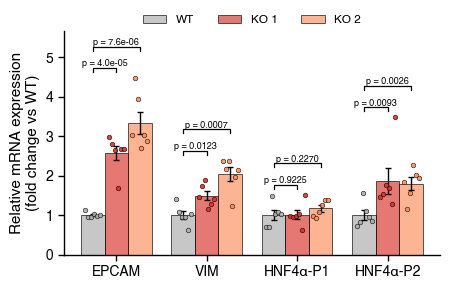

Saved: Fig_S10A_identity_markers_qPCR.pdf


In [4]:
x = np.arange(len(GENES)); w = 0.26; offs = {'WT': -w, 'KO 1': 0.0, 'KO 2': w}
fig, ax = plt.subplots(figsize=(4.6, 3.0))
cluster_top = []
for gi, g in enumerate(GENES):
    tops = []
    for grp in GROUP_ORDER:
        vals = qpcr[(qpcr.gene == g) & (qpcr.group == grp)]['rel_expression'].values
        mn, se = vals.mean(), sem(vals)
        xc = gi + offs[grp]
        ax.bar(xc, mn, width=w, color=COLORS[grp], alpha=0.65, edgecolor='black',
               linewidth=0.7, zorder=2, label=grp if gi == 0 else None)
        ax.errorbar(xc, mn, yerr=se, color='black', linewidth=1.0, capsize=2.5, ls='none', zorder=3)
        sp = np.linspace(-w*0.32, w*0.32, len(vals))
        ax.scatter(xc + sp, vals, color=COLORS[grp], edgecolors='black', linewidth=0.4, s=11, zorder=4, alpha=0.9)
        tops.append(max(mn + se, vals.max()))
    cluster_top.append(max(tops))
    # significance brackets, WT vs each KO, stacked above the cluster
    base = max(tops) + 0.15
    sig_bar(ax, gi + offs['WT'], gi + offs['KO 1'], base, P[(g, 'WT vs KO 1')], h=0.10, fs=6.5)
    sig_bar(ax, gi + offs['WT'], gi + offs['KO 2'], base + 0.55, P[(g, 'WT vs KO 2')], h=0.10, fs=6.5)

ax.set_xticks(x); ax.set_xticklabels(LABELS, fontstyle='italic')
ax.set_ylabel('Relative mRNA expression\n(fold change vs WT)', fontsize=AXTITLE)
ax.set_ylim(0, max(cluster_top) + 1.2)
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.12))
plt.tight_layout()
fig.savefig('Fig_S10A_identity_markers_qPCR.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig_S10A_identity_markers_qPCR.pdf')

## Panel 4B — HNF4A adult (P1) vs foetal (P2) promoter usage from RNA-seq coverage

RNA-seq read coverage over the HNF4A adult (P1) and foetal (P2) first-exon promoters (BPM-normalised
bigWig means), per replicate. **Main panel:** foetal isoform fraction = P2 / (P1 + P2). **Supplementary:**
the two promoters quantified separately. n = 6 per group.

**Statistics:** unpaired Welch's t-test (WT vs each KO), on the linear scale — the foetal fraction is a
proportion and the coverage values are absolute (BPM), so neither is a ratio-to-1 (no log2). Exact
p-values shown.


In [5]:
df = pd.read_csv('Fig4B_HNF4A_isoform_usage_data.csv')


### Main panel — foetal isoform fraction  P2 / (P1 + P2)  [narrow]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


{'KO1': '4.87e-05', 'KO2': '2.82e-03'}


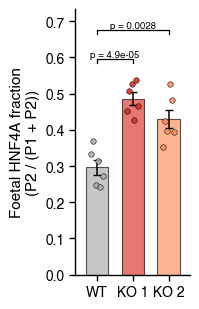

Saved: Fig4B_HNF4A_foetal_fraction.pdf


In [6]:
wt = df[df.group == 'WT']['fetal_fraction'].values
pm = {}
for ko in ['KO1', 'KO2']:
    kv = df[df.group == ko]['fetal_fraction'].values
    pm[ko] = stats.ttest_ind(wt, kv, equal_var=False).pvalue
print({k: f'{v:.2e}' for k, v in pm.items()})

fig, ax = plt.subplots(figsize=(2.1, 3.2))          # deliberately narrow
for i, g in enumerate(ORDER):
    v = df[df.group == g]['fetal_fraction'].values
    ax.bar(i, v.mean(), width=0.62, color=COLORS[g], alpha=0.65, edgecolor='black', linewidth=0.8, zorder=2)
    ax.errorbar(i, v.mean(), yerr=sem(v), color='black', linewidth=1.1, capsize=3, ls='none', zorder=3)
    ax.scatter(i + np.linspace(-0.16, 0.16, len(v)), v, color=COLORS[g], edgecolors='black',
               linewidth=0.4, s=16, zorder=4, alpha=0.9)
top = max(df.groupby('group')['fetal_fraction'].max()) + max(df.groupby('group')['fetal_fraction'].apply(sem))
sig_bar(ax, 0, 1, top + 0.02, pm['KO1'], h=0.012)
sig_bar(ax, 0, 2, top + 0.10, pm['KO2'], h=0.012)
ax.set_xticks(range(3)); ax.set_xticklabels([XLAB[g] for g in ORDER])
ax.set_ylabel('Foetal HNF4A fraction\n(P2 / (P1 + P2))', fontsize=AXTITLE)
ax.set_xlim(-0.6, 2.6); ax.set_ylim(0, top + 0.17)
plt.tight_layout()
fig.savefig('Fig4B_HNF4A_foetal_fraction.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig4B_HNF4A_foetal_fraction.pdf')


### Supplementary — adult (P1) and foetal (P2) promoter coverage, separately


          isoform Comparison  Mean WT  Mean KO           p
 HNF4A-P1 (adult)  WT vs KO1    0.630    0.726  p = 0.0888
 HNF4A-P1 (adult)  WT vs KO2    0.630    0.732  p = 0.1953
HNF4A-P2 (foetal)  WT vs KO1    0.262    0.687 p = 2.8e-06
HNF4A-P2 (foetal)  WT vs KO2    0.262    0.543 p = 2.2e-06


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


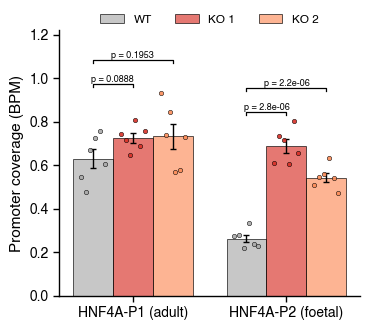

Saved: Fig_S10C_HNF4A_isoform_coverage.pdf


In [7]:
isoforms = [('adult_P1_BPM', 'HNF4A-P1 (adult)'), ('fetal_P2_BPM', 'HNF4A-P2 (foetal)')]
rows = []
for col, name in isoforms:
    wt = df[df.group == 'WT'][col].values
    for ko in ['KO1', 'KO2']:
        kv = df[df.group == ko][col].values
        rows.append({'isoform': name, 'Comparison': f'WT vs {ko}',
                     'Mean WT': round(wt.mean(), 3), 'Mean KO': round(kv.mean(), 3),
                     'p': stats.ttest_ind(wt, kv, equal_var=False).pvalue})
stats_supp = pd.DataFrame(rows); ps = {(r.isoform, r.Comparison): r.p for _, r in stats_supp.iterrows()}
disp = stats_supp.copy(); disp['p'] = disp['p'].apply(fmt_p); print(disp.to_string(index=False))

x = np.arange(2); w = 0.26; offs = {'WT': -w, 'KO1': 0.0, 'KO2': w}
fig, ax = plt.subplots(figsize=(3.8, 3.4))
for xi, (col, name) in enumerate(isoforms):
    for g in ORDER:
        v = df[df.group == g][col].values
        xc = xi + offs[g]
        ax.bar(xc, v.mean(), width=w, color=COLORS[g], alpha=0.65, edgecolor='black', linewidth=0.7,
               zorder=2, label=XLAB[g] if xi == 0 else None)
        ax.errorbar(xc, v.mean(), yerr=sem(v), color='black', linewidth=1.0, capsize=2.5, ls='none', zorder=3)
        ax.scatter(xc + np.linspace(-w*0.3, w*0.3, len(v)), v, color=COLORS[g], edgecolors='black',
                   linewidth=0.4, s=10, zorder=4, alpha=0.9)
    gmax = df[df[col] == df[col]].loc[df.group.isin(ORDER)].groupby('group')[col].max().max()
    base = gmax + 0.03
    sig_bar(ax, xi + offs['WT'], xi + offs['KO1'], base, ps[(name, 'WT vs KO1')], h=0.015, fs=6.5)
    sig_bar(ax, xi + offs['WT'], xi + offs['KO2'], base + 0.11, ps[(name, 'WT vs KO2')], h=0.015, fs=6.5)
ax.set_xticks(x); ax.set_xticklabels([n for _, n in isoforms])
ax.set_ylabel('Promoter coverage (BPM)', fontsize=AXTITLE)
ax.set_ylim(0, 1.22)
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.10))
plt.tight_layout()
fig.savefig('Fig_S10C_HNF4A_isoform_coverage.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig_S10C_HNF4A_isoform_coverage.pdf')


## Candidate upstream pathways for the dedifferentiation phenotype (not yet assigned a Supp. Fig. number -- flag for the SI renumbering pass)

**Question.** Panels 4B (HNF4A adult-to-foetal isoform switch) and the identity-marker qPCR above (EPCAM
up, VIM up) show that SLC38A4-KO cells lose mature hepatocyte identity. What pathway-level signal in the
same KO-vs-WT RNA-seq might sit upstream of that switch?

**Approach.** This reuses the Reactome GSEA already computed for Fig 3D/Table S6 in
`Fig3_KO_RNAseq_metabolism.ipynb` (same DE contrast, same ranking) -- read here from the shared cache
(`enrichment_cache_FDR0.05_FC1/_cache_prerank_opt7_reactome_gsea.csv`) rather than recomputed, so this
panel is guaranteed consistent with Fig 3D/Table S6. A reviewer-facing dump of the top hits from *all* 9
enrichment analyses already exists as `SuppFig_all_pathway_enrichment_overview.pdf` (Fig3 notebook); this
panel instead curates two specific, FDR<0.05, thematically coherent blocks that are candidate drivers of
the Fig 4 phenotype and are not otherwise shown anywhere in the manuscript (none of these terms overlap
Fig 3D's curated KEGG list):

- **Amino-acid sensing / mTORC1 / translation (down in KO)** -- consistent with the direct, expected
  consequence of losing an amino-acid transporter: less intracellular substrate blunts mTORC1 and triggers
  the GCN2-mediated integrated stress response, suppressing cap-dependent translation. mTORC1 signalling is
  an established regulator of hepatocyte differentiation state, making this a defensible candidate
  upstream driver rather than only a downstream consequence of dedifferentiation.
- **p53 / DNA-damage checkpoint / senescence (up in KO)** -- alongside the proliferation-arrest signature
  already shown in Panel 4D (MYC/CCND1 down, CDKN1A/CDKN2A up), this indicates the arrest has an active
  checkpoint/senescence character rather than simple quiescence.

**Caveat.** This is bulk RNA-seq pathway enrichment, not a functional perturbation -- it identifies
candidate associations, not proven causal drivers. Framed here as "candidate pathways", not "the mechanism".

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


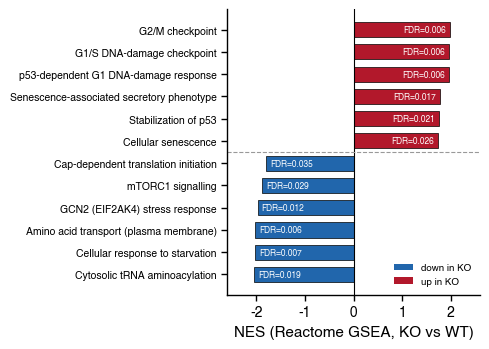

Saved: SuppFig_dedifferentiation_pathway_candidates.pdf
                                    label          block       NES      FDR
            Cytosolic tRNA aminoacylation        aa_mtor -2.042240 0.019117
          Cellular response to starvation        aa_mtor -2.027371 0.007080
   Amino acid transport (plasma membrane)        aa_mtor -2.020291 0.006372
           GCN2 (EIF2AK4) stress response        aa_mtor -1.971426 0.012037
                        mTORC1 signalling        aa_mtor -1.881829 0.028828
     Cap-dependent translation initiation        aa_mtor -1.799891 0.034528
                      Cellular senescence p53_senescence  1.727121 0.025617
                     Stabilization of p53 p53_senescence  1.750410 0.020755
Senescence-associated secretory phenotype p53_senescence  1.776784 0.016855
     p53-dependent G1 DNA-damage response p53_senescence  1.952127 0.006082
               G1/S DNA-damage checkpoint p53_senescence  1.966020 0.005562
                          G2/M c

In [8]:
# same down/up palette as Fig3_KO_RNAseq_metabolism.ipynb, defined locally here since this
# notebook's own house style (COLORS dict above) doesn't define C_DOWN/C_UP
C_DOWN, C_UP = '#2166AC', '#B2182B'

reactome_gsea = pd.read_csv('enrichment_cache_FDR0.05_FC1/_cache_prerank_opt7_reactome_gsea.csv',
                            index_col='Term')

CANDIDATE_TERMS = [
    # (exact Reactome term, short label, thematic block)
    ('Cellular Response To Starvation R-HSA-9711097',              'Cellular response to starvation',        'aa_mtor'),
    ('Cytosolic tRNA Aminoacylation R-HSA-379716',                  'Cytosolic tRNA aminoacylation',           'aa_mtor'),
    ('Amino Acid Transport Across Plasma Membrane R-HSA-352230',    'Amino acid transport (plasma membrane)',  'aa_mtor'),
    ('Response Of EIF2AK4 (GCN2) To Amino Acid Deficiency R-HSA-9633012', 'GCN2 (EIF2AK4) stress response',    'aa_mtor'),
    ('mTORC1-mediated Signaling R-HSA-166208',                      'mTORC1 signalling',                      'aa_mtor'),
    ('Cap-dependent Translation Initiation R-HSA-72737',            'Cap-dependent translation initiation',    'aa_mtor'),
    ('G2/M Checkpoints R-HSA-69481',                                'G2/M checkpoint',                         'p53_senescence'),
    ('G1/S DNA Damage Checkpoints R-HSA-69615',                     'G1/S DNA-damage checkpoint',              'p53_senescence'),
    ('p53-Dependent G1 DNA Damage Response R-HSA-69563',            'p53-dependent G1 DNA-damage response',    'p53_senescence'),
    ('Senescence-Associated Secretory Phenotype (SASP) R-HSA-2559582', 'Senescence-associated secretory phenotype', 'p53_senescence'),
    ('Stabilization Of P53 R-HSA-69541',                            'Stabilization of p53',                    'p53_senescence'),
    ('Cellular Senescence R-HSA-2559583',                           'Cellular senescence',                     'p53_senescence'),
]
BLOCK_LABEL = {'aa_mtor': 'Amino-acid sensing / mTORC1 / translation', 'p53_senescence': 'p53 / DNA-damage checkpoint / senescence'}

rows = []
for term, label, block in CANDIDATE_TERMS:
    r = reactome_gsea.loc[term]
    rows.append({'term': term, 'label': label, 'block': block,
                 'NES': float(r['NES']), 'FDR': float(r['FDR q-val'])})
cand = pd.DataFrame(rows).sort_values('NES').reset_index(drop=True)
cand.to_csv('SuppFig_dedifferentiation_pathway_candidates_data.csv', index=False)

y = np.arange(len(cand))
colors = [C_DOWN if v < 0 else C_UP for v in cand['NES']]
fig, ax = plt.subplots(figsize=(5.0, 3.6))
ax.barh(y, cand['NES'], color=colors, edgecolor='black', linewidth=0.5, height=0.68, zorder=2)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(cand['label'], fontsize=7.5)
for yi, (nes, fdr) in enumerate(zip(cand['NES'], cand['FDR'])):
    ax.text(nes - 0.08 if nes > 0 else nes + 0.08, yi, f'FDR={fdr:.3f}',
            va='center', ha='right' if nes > 0 else 'left', fontsize=6, color='white')
# divider + block labels between the two thematic groups
n_down = (cand['NES'] < 0).sum()
ax.axhline(n_down - 0.5, color='0.6', lw=0.8, ls='--')
ax.set_xlabel('NES (Reactome GSEA, KO vs WT)', fontsize=AXTITLE)
ax.set_xlim(-2.6, 2.6)
ax.legend(handles=[Patch(facecolor=C_DOWN, label='down in KO'), Patch(facecolor=C_UP, label='up in KO')],
          frameon=False, fontsize=7, loc='lower right')
plt.tight_layout()
fig.savefig('SuppFig_dedifferentiation_pathway_candidates.pdf', bbox_inches='tight'); plt.show()
print('Saved: SuppFig_dedifferentiation_pathway_candidates.pdf')
print(cand[['label','block','NES','FDR']].to_string(index=False))

## Panel S10D — CCK-8 proliferation assay

**CCK-8 growth** of WT vs KO 1 vs KO 2.

Well-level replicate data (n=7-8 wells/group/timepoint; single wells excluded per the source lab's own
QC are already removed from this file). Individual wells are shown as jittered points, with mean ± SEM
overlaid; WT vs each KO clone compared per timepoint by unpaired, two-tailed Welch's t-test on
log2-transformed values relative to baseline (t = 0), consistent with Supplementary Methods Section 6.8 and Section 7 (Statistical analysis).


### CCK-8 growth curve


,time_h,Comparison,n_WT,n_KO,Mean WT,Mean KO,p
0,0.0,WT vs KO 1,8,7,1.000,1.000,p = 0.9718
1,0.0,WT vs KO 2,8,8,1.000,1.000,p = 0.9822
2,23.0,WT vs KO 1,8,8,1.237,1.159,p = 4.7e-05
3,23.0,WT vs KO 2,8,7,1.237,1.192,p = 0.0324
4,46.0,WT vs KO 1,8,8,1.673,1.490,p = 6.1e-05
5,46.0,WT vs KO 2,8,7,1.673,1.489,p = 1.2e-05
6,70.0,WT vs KO 1,8,7,2.710,2.105,p = 8.4e-08
7,70.0,WT vs KO 2,8,7,2.710,2.072,p = 2.5e-09


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


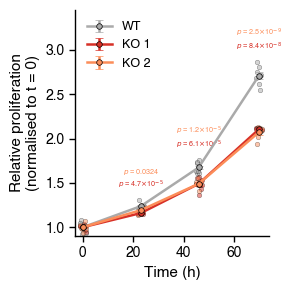

Saved: Fig_S10D_CCK8_proliferation.pdf  (individual wells + mean +/- SEM + WT-vs-KO significance)


In [11]:
cck = pd.read_csv('Fig_S10D_CCK8_proliferation_data.csv')
GROUP_ORDER_CCK = ['WT', 'KO 1', 'KO 2']

# summary (mean +/- SEM) per group/timepoint
summary_cck = (cck.groupby(['time_h', 'group'])['rel_proliferation']
                  .agg(n='count', mean='mean', sem=sem).reset_index())

# stats: unpaired, two-tailed Welch's t-test on log2-transformed values, WT vs each KO, per timepoint
rows = []
for t_h in sorted(cck.time_h.unique()):
    wt = cck[(cck.time_h == t_h) & (cck.group == 'WT')]['rel_proliferation'].values
    for ko in ['KO 1', 'KO 2']:
        kv = cck[(cck.time_h == t_h) & (cck.group == ko)]['rel_proliferation'].values
        t, p = stats.ttest_ind(np.log2(wt), np.log2(kv), equal_var=False)
        rows.append({'time_h': t_h, 'Comparison': f'WT vs {ko}', 'n_WT': len(wt), 'n_KO': len(kv),
                     'Mean WT': round(wt.mean(), 3), 'Mean KO': round(kv.mean(), 3), 'p': p})
stats_cck = pd.DataFrame(rows)
P_cck = {(r.time_h, r.Comparison): r.p for _, r in stats_cck.iterrows()}
disp = stats_cck.copy(); disp['p'] = disp['p'].apply(fmt_p); display(disp)

np.random.seed(42)
fig, ax = plt.subplots(figsize=(3, 3))
for g in GROUP_ORDER_CCK:
    d = cck[cck.group == g]
    jit = np.random.uniform(-1.3, 1.3, size=len(d))
    ax.scatter(d['time_h'] + jit, d['rel_proliferation'], color=COLORS[g],
               edgecolors='black', linewidth=0.3, s=11, alpha=0.5, zorder=2)
for g in GROUP_ORDER_CCK:
    s = summary_cck[summary_cck.group == g].sort_values('time_h')
    ax.errorbar(s['time_h'], s['mean'], yerr=s['sem'], marker='o', markersize=4,
                color=COLORS[g], markeredgecolor='black', markeredgewidth=0.5,
                linewidth=1.8, capsize=3, capthick=1.0, label=g, zorder=3)

# significance
def fmt_p_fig(p):
    """Figure-style p-value with a real superscript, matching panels A/C."""
    if p >= 1e-4:
        return f'$p$ = {p:.4f}'
    e = int(np.floor(np.log10(p))); m = p / 10**e
    return f'$p$ = {m:.1f}$\\times$10$^{{{e}}}$'

local_top = cck.groupby('time_h')['rel_proliferation'].max()
for t_h in [23., 46., 70.]:
    for ko, dy in [('KO 1', 0.0), ('KO 2', 0.16)]:
        ax.text(t_h, local_top.loc[t_h] + 0.10 + dy, fmt_p_fig(P_cck[(t_h, f'WT vs {ko}')]),
                ha='center', va='bottom', fontsize=5.2, color=COLORS[ko])

ax.set_xlabel('Time (h)', fontsize=AXTITLE)
ax.set_ylabel('Relative proliferation\n(normalised to t = 0)', fontsize=AXTITLE)
ax.set_xticks([0, 20, 40, 60])
ax.set_xlim(-3, 74)
ax.set_ylim(0.9, 3.45)
ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout()
fig.savefig('Fig_S10D_CCK8_proliferation.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig_S10D_CCK8_proliferation.pdf  (individual wells + mean +/- SEM + WT-vs-KO significance)')


## Panel 4D — Cell-cycle/checkpoint gene signature (RNA-seq, KO vs WT)

Curated panel spanning three groups: proliferation drivers (down in KO), checkpoint-activation genes and
CDK inhibitors/senescence markers (both up in KO). The checkpoint and inhibitor/senescence genes were
chosen as the most recognisable, individually significant representatives of the leading-edge genes from
the unbiased p53-stabilisation / G1-S / G2-M checkpoint / cellular-senescence / SASP Reactome GSEA terms
(see `SuppFig_dedifferentiation_pathway_candidates`); the leading edges themselves are dominated by
generic proteasome-subunit genes not suited to a labelled illustrative panel, so a small set of
well-known pathway members was selected instead. All genes shown are significant at FDR < 0.05 except
MKI67 (FDR = 0.063, shown faded), which is retained for continuity with the CCK-8 proliferation result
above.


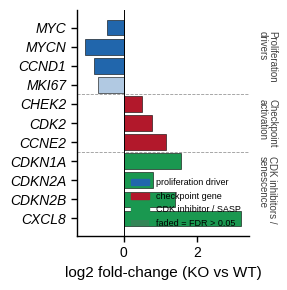

Saved: Fig4D_proliferation_genes.pdf


,gene,role,group,logFC,FDR
0,CXCL8,inhibitor,CDK inhibitors /\nsenescence,3.216174,1.332669e-09
1,CDKN2B,inhibitor,CDK inhibitors /\nsenescence,1.409997,6.804720e-16
2,CDKN2A,inhibitor,CDK inhibitors /\nsenescence,0.797741,2.775272e-13
3,CDKN1A,inhibitor,CDK inhibitors /\nsenescence,1.565340,3.041365e-11
4,CCNE2,checkpoint,Checkpoint\nactivation,1.143202,3.005476e-09
5,CDK2,checkpoint,Checkpoint\nactivation,0.773347,8.140044e-15
6,CHEK2,checkpoint,Checkpoint\nactivation,0.487828,7.144655e-10
7,MKI67,driver,Proliferation\ndrivers,-0.692720,6.304551e-02
8,CCND1,driver,Proliferation\ndrivers,-0.810130,5.601613e-14
9,MYCN,driver,Proliferation\ndrivers,-1.072798,6.530259e-10


In [10]:
from matplotlib.transforms import blended_transform_factory

de = (pd.read_csv('Fig3C_limma_KO_vs_WT_combined_mincount10.csv', index_col=0)
        .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))

# Expanded panel: proliferation drivers (down) plus two up-regulated groups reflecting the
# checkpoint-activation / senescence signal independently supported by the unbiased Reactome GSEA
# (p53 stabilisation, G1/S + G2/M checkpoints, cellular senescence, SASP). See markdown above for
# how these specific genes were chosen.
CCGENES = [
    ('MYC',    'driver',     'Proliferation\ndrivers'),
    ('MYCN',   'driver',     'Proliferation\ndrivers'),
    ('CCND1',  'driver',     'Proliferation\ndrivers'),
    ('MKI67',  'driver',     'Proliferation\ndrivers'),
    ('CHEK2',  'checkpoint', 'Checkpoint\nactivation'),
    ('CDK2',   'checkpoint', 'Checkpoint\nactivation'),
    ('CCNE2',  'checkpoint', 'Checkpoint\nactivation'),
    ('CDKN1A', 'inhibitor',  'CDK inhibitors /\nsenescence'),
    ('CDKN2A', 'inhibitor',  'CDK inhibitors /\nsenescence'),
    ('CDKN2B', 'inhibitor',  'CDK inhibitors /\nsenescence'),
    ('CXCL8',  'inhibitor',  'CDK inhibitors /\nsenescence'),
]
rows = [{'gene': g, 'role': role, 'group': grp, 'logFC': de.loc[g, 'logFC'], 'FDR': de.loc[g, 'adj.P.Val']}
        for g, role, grp in CCGENES if g in de.index]
cc = pd.DataFrame(rows).iloc[::-1].reset_index(drop=True)          # first gene at top
cc.to_csv('Fig4E_proliferation_genes_plotted.csv', index=False)        # export plotted values

y = np.arange(len(cc)); A = 0.35
role_col = {'driver': '#2166AC', 'checkpoint': '#B2182B', 'inhibitor': '#1a9850'}
colors = [to_rgba(role_col[r], 1.0 if f < 0.05 else A) for r, f in zip(cc['role'], cc['FDR'])]

fig, ax = plt.subplots(figsize=(3, 3))
ax.barh(y, cc['logFC'], color=colors, edgecolor='black', linewidth=0.4)
ax.axvline(0, color='k', lw=0.7)
ax.set_yticks(y); ax.set_yticklabels(cc['gene'], fontstyle='italic')
ax.set_xlabel('log2 fold-change (KO vs WT)', fontsize=AXTITLE)

# dashed divider between the three thematic blocks
for i in range(1, len(cc)):
    if cc['group'].iloc[i] != cc['group'].iloc[i - 1]:
        ax.axhline(i - 0.5, color='0.6', lw=0.6, linestyle='--', zorder=0)

# side label per thematic group, just outside the right edge of the axes
trans = blended_transform_factory(ax.transAxes, ax.transData)
for grp in cc['group'].unique():
    idx = cc.index[cc['group'] == grp]
    ymid = (idx.min() + idx.max()) / 2
    ax.text(1.05, ymid, grp, transform=trans, ha='left', va='center',
            fontsize=7, rotation=-90, color='0.25', linespacing=0.9)

ax.legend(handles=[Patch(color=role_col['driver'], label='proliferation driver'),
                   Patch(color=role_col['checkpoint'], label='checkpoint gene'),
                   Patch(color=role_col['inhibitor'], label='CDK inhibitor / SASP'),
                   Patch(facecolor='0.4', alpha=A, label='faded = FDR > 0.05')],
          fontsize=6.5, frameon=False, loc='lower right', bbox_to_anchor=(1.0, 0.0))
plt.tight_layout()
fig.savefig('Fig4D_proliferation_genes.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig4D_proliferation_genes.pdf')
cc


## Panel 4E — SLC38A4-KO vs SAH liver signature (pre-ranked GSEA)

**Question.** Does the SLC38A4-knockout Huh7.5 transcriptome recapitulate the transcriptional programme
of severe alcohol-related hepatitis (SAH) patient livers?

**Approach.** Genes are ranked by the KO-vs-WT moderated *t*-statistic (limma-voom, min.count = 10). An
SAH up/down signature (top/bottom 200 protein-coding genes of the InTEAM SAH-vs-Normal DESeq2 contrast by
Wald statistic, padj < 0.05; non-coding-RNA classes removed and genes required to be measured in both
datasets) is tested against that ranked list by pre-ranked GSEA (gseapy). Directional concordance =
SAH-up genes enriched among KO-up, SAH-down among KO-down.

**Reproducibility.** The GSEA (permutation-based) writes three tidy CSVs; the figure cells read those
CSVs, so re-plotting never re-runs the permutations. The tidy CSVs are distributed with this notebook —
set `RECOMPUTE = True` below only if you have the raw DE tables locally (not redistributed with the
repo) and want to regenerate them (bump `NPERM` to 10000 for the final publication run).


In [11]:
RECOMPUTE = False         # True only if you have the raw DE tables locally (see KO_FILE / SAH_FILE)
NPERM     = 100000       # permutations for the final run
SEED      = 42
N         = 200          # size of the SAH up/down signature

KO_FILE   = '../05_Data/RNAseq/SLC38A4_KO_RNA-seq/limma_KO_vs_WT_combined_mincount10.csv'
SAH_FILE  = '../05_Data/RNAseq/inteam_res_complete_20251023.xlsx'
SAH_SHEET = 'AH_vs_normal'

STATS_CSV = 'Fig4E_GSEA_stats.csv'
RUN_CSV   = 'Fig4E_GSEA_running.csv'
SIG_CSV   = 'Fig4E_SAH_signature_genes.csv'
C_UP, C_DN = '#F16913', '#2171B5'   # SAH-up (orange), SAH-down (blue)

def fmt_fdr(q):
    """FDR q-value label; exact zero from finite permutations shown as an upper bound."""
    return 'FDR < 1e-4' if q == 0 else f'FDR = {q:.1e}'

if RECOMPUTE:
    import re
    import gseapy as gp
    ko = (pd.read_csv(KO_FILE, index_col=0)
            .dropna(subset=['gene_symbol']).drop_duplicates('gene_symbol').set_index('gene_symbol'))
    sah = (pd.read_excel(SAH_FILE, sheet_name=SAH_SHEET, engine='openpyxl')
             .dropna(subset=['symbol']).drop_duplicates('symbol').set_index('symbol'))

    NC = re.compile(r"^(LOC\d+|LINC\d+|MIR\d.*|MIRLET.*|MIR\w+HG|SNOR\w+|SCARNA\d+|"
                    r"RNU\d\w*|RN7S\w+|RNA5S\w*|VTRNA\w*|RMRP)$|(-AS\d+$)|(-DT$)")
    keep = [g for g in sah.index if (g in ko.index) and not NC.search(str(g))]
    sig = sah.loc[keep]
    sig = sig[sig['padj'] < 0.05]
    up = list(sig.sort_values('stat').tail(N).index)
    dn = list(sig.sort_values('stat').head(N).index)
    os.makedirs('_gsea_tmp', exist_ok=True)
    gmt = '_gsea_tmp/SAH_signature.gmt'
    with open(gmt, 'w') as fh:
        fh.write('SAH_UP\tSAH_up\t'   + '\t'.join(map(str, up)) + '\n')
        fh.write('SAH_DOWN\tSAH_down\t' + '\t'.join(map(str, dn)) + '\n')

    rng = np.random.default_rng(SEED)
    rnk = (ko['t'].astype(float) + rng.normal(0, 1e-9, len(ko))).sort_values(ascending=False)
    rnk_df = rnk.reset_index(); rnk_df.columns = ['gene', 'score']

    pre = gp.prerank(rnk=rnk_df, gene_sets=gmt, min_size=5, max_size=500,
                     permutation_num=NPERM, outdir=None, seed=SEED, verbose=False)
    res = pre.res2d.copy(); res.columns = [c.strip() for c in res.columns]
    tc = 'Term' if 'Term' in res.columns else res.columns[0]
    res = res.set_index(tc)
    for c in ['NES', 'ES', 'FDR q-val', 'NOM p-val']:
        if c in res.columns: res[c] = pd.to_numeric(res[c], errors='coerce')
    res.reset_index()[[tc] + [c for c in ['ES','NES','NOM p-val','FDR q-val'] if c in res.columns]] \
       .to_csv(STATS_CSV, index=False)

    ranked = rnk.values
    run = pd.DataFrame({'rank': np.arange(len(ranked)), 'ranked_metric': ranked})
    for term in ['SAH_UP', 'SAH_DOWN']:
        run[f'RES_{term}'] = np.asarray(pre.results[term]['RES'], dtype=float)
        hm = np.zeros(len(ranked), dtype=int); hm[np.asarray(pre.results[term]['hits'], dtype=int)] = 1
        run[f'hit_{term}'] = hm
    run.to_csv(RUN_CSV, index=False)
    pd.DataFrame({'SAH_UP': pd.Series(up), 'SAH_DOWN': pd.Series(dn)}).to_csv(SIG_CSV, index=False)
    print('Recomputed GSEA CSVs.')
else:
    print('RECOMPUTE = False — plotting from the tidy CSVs distributed with this notebook.')


RECOMPUTE = False — plotting from the tidy CSVs distributed with this notebook.


### Classic running-enrichment plot (SAH-up and SAH-down in the KO ranked list)


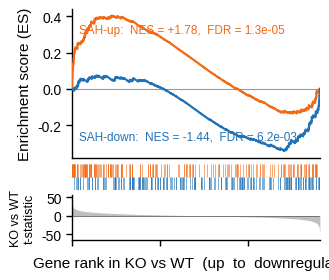

Saved: Fig4E_GSEA_KO_vs_SAH.pdf


In [12]:
stats_ = pd.read_csv(STATS_CSV).set_index('Term')
run   = pd.read_csv(RUN_CSV)
n = len(run); x = run['rank'].values
def stat(term, col): return float(stats_.loc[term, col])

fig = plt.figure(figsize=(3.2, 3))
gs = fig.add_gridspec(3, 1, height_ratios=[4.0, 0.7, 1.2], hspace=0.08)

ax0 = fig.add_subplot(gs[0])
ax0.plot(x, run['RES_SAH_UP'],   color=C_UP, lw=1.6, zorder=3)
ax0.plot(x, run['RES_SAH_DOWN'], color=C_DN, lw=1.6, zorder=3)
ax0.axhline(0, color='0.6', lw=0.8)
ax0.set_ylabel('Enrichment score (ES)', fontsize=AXTITLE)
ax0.set_xlim(0, n); ax0.set_xticklabels([])
ax0.tick_params(axis='x', length=0)
ax0.text(0.03, 0.90, f"SAH-up:  NES = {stat('SAH_UP','NES'):+.2f},  {fmt_fdr(stat('SAH_UP','FDR q-val'))}",
         transform=ax0.transAxes, color=C_UP, fontsize=8.5, va='top')
ax0.text(0.03, 0.10, f"SAH-down:  NES = {stat('SAH_DOWN','NES'):+.2f},  {fmt_fdr(stat('SAH_DOWN','FDR q-val'))}",
         transform=ax0.transAxes, color=C_DN, fontsize=8.5, va='bottom')

ax1 = fig.add_subplot(gs[1], sharex=ax0)
for xi in x[run['hit_SAH_UP'] == 1]:   ax1.vlines(xi, 0.5, 1.0, color=C_UP, lw=0.4)
for xi in x[run['hit_SAH_DOWN'] == 1]: ax1.vlines(xi, 0.0, 0.5, color=C_DN, lw=0.4)
ax1.set_ylim(0, 1); ax1.set_yticks([]); ax1.set_xlim(0, n)
ax1.tick_params(axis='x', length=0); ax1.set_xticklabels([])
for sp in ax1.spines.values(): sp.set_visible(False)

ax2 = fig.add_subplot(gs[2], sharex=ax0)
ax2.fill_between(x, run['ranked_metric'], 0, color='0.75', lw=0)
ax2.axhline(0, color='0.4', lw=0.6)
ax2.set_xlim(0, n); ax2.set_ylabel('KO vs WT\nt-statistic', fontsize=9)
ax2.set_xlabel('Gene rank in KO vs WT  (up  to  downregulated)', fontsize=AXTITLE)
ax2.spines['left'].set_visible(True)

plt.savefig('Fig4E_GSEA_KO_vs_SAH.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig4E_GSEA_KO_vs_SAH.pdf')


### Compact alternative — NES bar (same statistics)


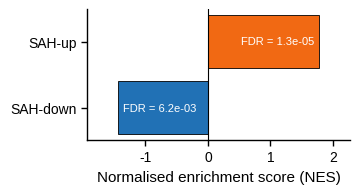

Saved: Fig4E_GSEA_NES_bar.pdf


In [13]:
order = ['SAH_DOWN', 'SAH_UP']; lab = {'SAH_UP': 'SAH-up', 'SAH_DOWN': 'SAH-down'}
nes = [stat(t, 'NES') for t in order]; fdr = [stat(t, 'FDR q-val') for t in order]
cols = [C_DN if v < 0 else C_UP for v in nes]
fig, ax = plt.subplots(figsize=(3.4, 1.7))
ax.barh([lab[t] for t in order], nes, color=cols, edgecolor='black', lw=0.6)
ax.axvline(0, color='black', lw=0.8)
for i, (v, q) in enumerate(zip(nes, fdr)):
    ax.text(v - 0.08 if v > 0 else v + 0.08, i, fmt_fdr(q),
            va='center', ha='right' if v > 0 else 'left', fontsize=8, color='white')
ax.set_xlabel('Normalised enrichment score (NES)', fontsize=AXTITLE)
ax.set_xlim(min(nes) - 0.5, max(nes) + 0.5)
plt.savefig('Fig4E_GSEA_NES_bar.pdf', bbox_inches='tight'); plt.show()
print('Saved: Fig4E_GSEA_NES_bar.pdf')
